# 5. Snap counts and injury reports

Notebook 4 showed that more seasons of the same data don't help the weekly model. Better *information* might.
Two candidates, both published before kickoff:

* **Snap share**: the fraction of the offense's plays a player was on the field for, in earlier games (nflverse, 2012+).
* **The injury report**: this week's game status (Questionable / Doubtful) and last practice participation.

Same setup as notebook 3: train 2021-2023, validate 2024, and the 2025 test. Since notebook 3 already looked at 2025, the
**2026 season so far** (weeks 4-7) is used as a fresh test that no modeling choice has seen.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fantasy.features import TARGET, model_sample
from fantasy.evaluate import score_table, pairwise_accuracy
from fantasy import plots as P

P.use_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
from fantasy.weekly import BASE, FULL, fit, prepare, weekly_frame
from fantasy.features import SNAP_FEATURES, INJURY_FEATURES

In [2]:
df = weekly_frame(range(2020, 2027))
sample = prepare(model_sample(df[df.season >= 2021]))
print(f"{len(sample):,} player-games, 2021-2026 (2026 through week {sample[sample.season == 2026].week.max()})")
print("missing snap share:", sample[SNAP_FEATURES].isna().mean().round(3).to_dict())
sample[["player_display_name", "season", "week", "snap_last", "snap_last3", "snap_avg"] + INJURY_FEATURES].sample(5, random_state=3)

13,747 player-games, 2021-2026 (2026 through week 7)
missing snap share: {'snap_last': 0.0, 'snap_last3': 0.0, 'snap_avg': 0.0}


,player_display_name,season,week,snap_last,snap_last3,snap_avg,questionable,doubtful,practice_dnp,practice_limited
14390,DJ Moore,2026,4,0.64,0.570,0.570,0,0,0,1
10130,Evan Engram,2025,16,0.28,0.393,0.431,0,0,0,0
35600,Caleb Williams,2024,10,1.00,0.983,0.989,0,0,0,0
21629,Darnell Mooney,2024,4,0.93,0.960,0.960,0,0,0,0
18516,Marquise Brown,2025,16,0.34,0.377,0.509,0,0,0,0


## What an injury tag means

Players who suit up with an injury tag, compared with their season-to-date average (scaled so 100% = a typical
week; players score a bit under their average going forward):

In [3]:
hist = sample[sample.season <= 2025]
typical = hist[TARGET].sum() / hist.avg_season.sum()
def vs_avg(mask):
    d = hist[mask]
    return pd.Series({"vs. typical week": d[TARGET].sum() / d.avg_season.sum() / typical - 1, "player-games": len(d)})

tags = pd.DataFrame({
    "No injury report": vs_avg((hist.questionable == 0) & (hist.practice_dnp == 0) & (hist.practice_limited == 0)),
    "Limited in practice": vs_avg(hist.practice_limited == 1),
    "Questionable": vs_avg(hist.questionable == 1),
    "Missed practice (DNP)": vs_avg(hist.practice_dnp == 1),
}).T
tags

,vs. typical week,player-games
No injury report,0.010,11762.0
Limited in practice,-0.059,930.0
Questionable,-0.108,750.0
Missed practice (DNP),-0.146,280.0


PosixPath('/home/user/nfl-historic-analysis/reports/figures/12_injury_tags.png')

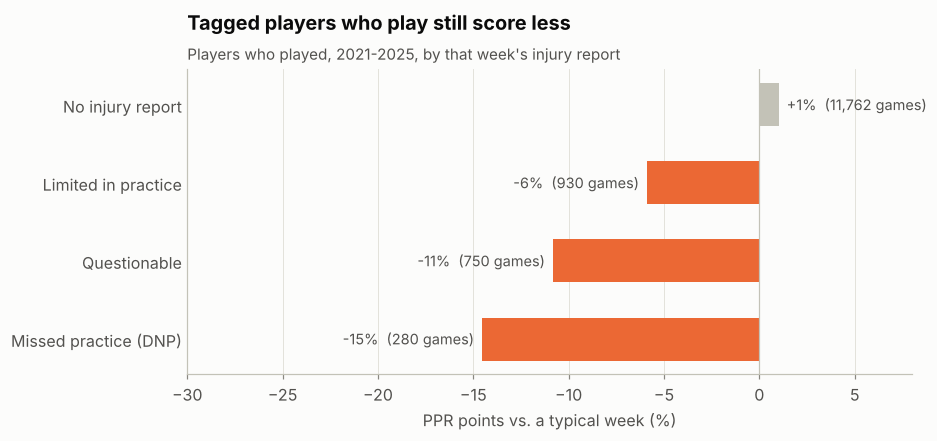

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
y = np.arange(len(tags))[::-1]
vals = tags["vs. typical week"].values * 100
ax.barh(y, vals, height=0.55, color=[P.GREY] + [P.ORANGE] * (len(tags) - 1))
for yi, v, n in zip(y, vals, tags["player-games"]):
    ax.text(v - 0.4 if v < 0 else v + 0.4, yi, f"{v:+.0f}%  ({int(n):,} games)", va="center",
            ha="right" if v < 0 else "left", color=P.INK_2, fontsize=9.5)
ax.axvline(0, color=P.GREY, linewidth=0.8)
ax.set_yticks(y, tags.index)
ax.tick_params(axis="y", length=0)
ax.set_xlim(-30, 8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("PPR points vs. a typical week (%)")
ax.set_title("Tagged players who play still score less", pad=26)
P.subtitle(ax, "Players who played, 2021-2025, by that week's injury report")
P.save(fig, "12_injury_tags")

## Does the model get better?

Four versions of the notebook 3 ridge model: the original features, plus snaps, plus injuries, plus both.

In [5]:
VARIANTS = {"Original": BASE, "+ snaps": BASE + SNAP_FEATURES, "+ injuries": BASE + INJURY_FEATURES, "+ both": FULL}
train = sample[sample.season.between(2021, 2023)]
evals = {"2024 (validation)": sample[sample.season == 2024], "2025 (test)": sample[sample.season == 2025],
         "2026 wk 4-7 (fresh)": sample[sample.season == 2026]}
models = {name: fit(train, num) for name, num in VARIANTS.items()}
rows = []
for name, num in VARIANTS.items():
    for label, d in evals.items():
        d = d.assign(pred=models[name].predict(d[num + ["position"]]))
        rows.append({"model": name, "season": label, "MAE": (d.pred - d[TARGET]).abs().mean(),
                     "start/sit": pairwise_accuracy(d, "pred", TARGET)})
compare = pd.DataFrame(rows).pivot(index="model", columns="season").loc[list(VARIANTS)]
compare.round(3)

MAE                                         start/sit                                
season     2024 (validation) 2025 (test) 2026 wk 4-7 (fresh) 2024 (validation) 2025 (test) 2026 wk 4-7 (fresh)
model                                                                                                         
Original               5.662       5.674               5.673             0.660       0.655               0.661
+ snaps                5.622       5.613               5.672             0.662       0.661               0.656
+ injuries             5.661       5.680               5.682             0.660       0.655               0.660
+ both                 5.621       5.624               5.680             0.664       0.660               0.656

Snaps help on 2024 and 2025, but those gains are small. Are they real or luck? **Bootstrap by week**: resample whole
weeks of the 2025 season with replacement 2,000 times and recompute how much MAE each version saves over the original.
Weeks, not single rows, because players in the same week share game conditions.

In [6]:
test = evals["2025 (test)"].copy()
for name, num in VARIANTS.items():
    test[name] = (models[name].predict(test[num + ["position"]]) - test[TARGET]).abs()
weekly = test.groupby("week")[list(VARIANTS)].agg(["sum", "count"])
rng = np.random.default_rng(0)
weeks = weekly.index.to_numpy()
boot = {name: [] for name in list(VARIANTS)[1:]}
for _ in range(2000):
    pick = rng.choice(weeks, size=len(weeks), replace=True)
    w = weekly.loc[pick]
    base_mae = w[("Original", "sum")].sum() / w[("Original", "count")].sum()
    for name in boot:
        boot[name].append(base_mae - w[(name, "sum")].sum() / w[(name, "count")].sum())
ci = pd.DataFrame({name: {"MAE saved": np.mean(v), "low (2.5%)": np.percentile(v, 2.5),
                          "high (97.5%)": np.percentile(v, 97.5), "share of resamples > 0": np.mean(np.array(v) > 0)}
                   for name, v in boot.items()}).T
ci.round(3)

,MAE saved,low (2.5%),high (97.5%),share of resamples > 0
+ snaps,0.061,0.030,0.096,1.000
+ injuries,-0.006,-0.018,0.009,0.212
+ both,0.051,0.016,0.094,1.000


PosixPath('/home/user/nfl-historic-analysis/reports/figures/13_snaps_injuries_bootstrap.png')

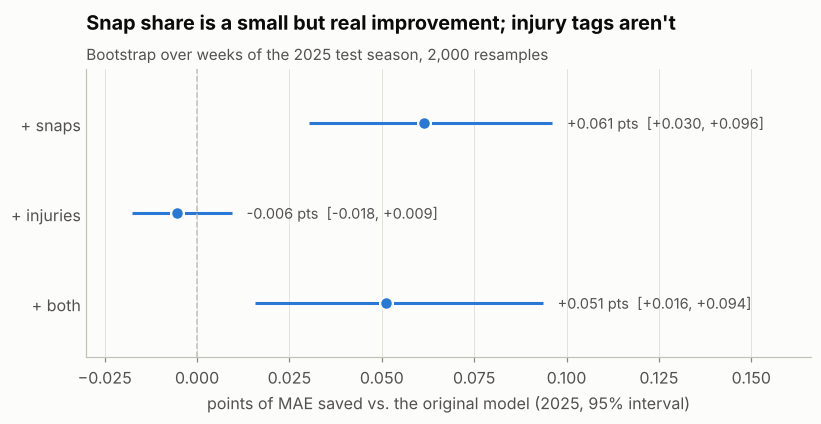

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
y = np.arange(len(ci))[::-1]
ax.hlines(y, ci["low (2.5%)"], ci["high (97.5%)"], color=P.BLUE, linewidth=2)
ax.scatter(ci["MAE saved"], y, s=70, color=P.BLUE, edgecolor=P.SURFACE, linewidth=1.5, zorder=3)
for yi, m, lo, hi in zip(y, ci["MAE saved"], ci["low (2.5%)"], ci["high (97.5%)"]):
    ax.text(hi + 0.004, yi, f"{m:+.3f} pts  [{lo:+.3f}, {hi:+.3f}]", va="center", color=P.INK_2, fontsize=9.5)
ax.axvline(0, color=P.GREY, linewidth=1, linestyle="--")
ax.set_yticks(y, ci.index)
ax.tick_params(axis="y", length=0)
ax.set_ylim(-0.6, len(ci) - 0.4)
ax.set_xlim(min(-0.03, ci["low (2.5%)"].min() - 0.01), ci["high (97.5%)"].max() + 0.07)
ax.grid(axis="y", visible=False)
ax.set_xlabel("points of MAE saved vs. the original model (2025, 95% interval)")
ax.set_title("Snap share is a small but real improvement; injury tags aren't", pad=26)
P.subtitle(ax, "Bootstrap over weeks of the 2025 test season, 2,000 resamples")
P.save(fig, "13_snaps_injuries_bootstrap")

## Takeaways

* **Snap share earns its place.** Adding it cuts error a little on both 2024 and 2025, and the interval for 2025 stays
  above zero. On the four 2026 weeks it's a wash, which is within the noise of 640 player-games.
* **Injury tags are real information that a season-wide average hides.** A questionable player who plays scores well
  under their norm, but only about 6% of player-games carry a tag, so they barely move overall accuracy. They still matter
  for the specific player you're deciding on, so the live model keeps them.
* The live projections (notebook 7) use the **+ both** model, which was best on the 2024 validation season.